# Motor Insurance Pricing: Claim Frequency Model

The goal of this project is to predict the expected number of claims per policy per year,
which is the frequency component of the pure premium (frequency × severity) used in motor insurance pricing.

Dataset: freMTPL2freq, French motor third-party liability portfolio (OpenML id 41214).

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_openml

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)

In [8]:
df = fetch_openml(data_id=41214, as_frame=True).frame

# Text columns come wrapped in quotes, e.g. "'Diesel'"
text_cols = df.select_dtypes(exclude="number").columns
for col in text_cols:
    df[col] = df[col].astype(str).str.strip("'")

df["IDpol"] = df["IDpol"].astype(int)
df["ClaimNb"] = df["ClaimNb"].astype(int)

print(df.shape)
df.head()

(678013, 12)


,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region
0,1,1,0.10,D,5,0,55,50,B12,Regular,1217,R82
1,3,1,0.77,D,5,0,55,50,B12,Regular,1217,R82
2,5,1,0.75,B,6,2,52,50,B12,Diesel,54,R22
3,10,1,0.09,B,7,0,46,50,B12,Diesel,76,R72
4,11,1,0.84,B,7,0,46,50,B12,Diesel,76,R72


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 678013 entries, 0 to 678012
Data columns (total 12 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   IDpol       678013 non-null  int64  
 1   ClaimNb     678013 non-null  int64  
 2   Exposure    678013 non-null  float64
 3   Area        678013 non-null  str    
 4   VehPower    678013 non-null  int64  
 5   VehAge      678013 non-null  int64  
 6   DrivAge     678013 non-null  int64  
 7   BonusMalus  678013 non-null  int64  
 8   VehBrand    678013 non-null  str    
 9   VehGas      678013 non-null  str    
 10  Density     678013 non-null  int64  
 11  Region      678013 non-null  str    
dtypes: float64(1), int64(7), str(4)
memory usage: 62.1 MB


In [10]:
df.describe()

,IDpol,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,Density
count,6.780130e+05,678013.000000,678013.000000,678013.000000,678013.000000,678013.000000,678013.000000,678013.000000
mean,2.621857e+06,0.053247,0.528750,6.454631,7.044265,45.499122,59.761502,1792.422405
std,1.641783e+06,0.240117,0.364442,2.050906,5.666232,14.137444,15.636658,3958.646564
min,1.000000e+00,0.000000,0.002732,4.000000,0.000000,18.000000,50.000000,1.000000
25%,1.157951e+06,0.000000,0.180000,5.000000,2.000000,34.000000,50.000000,92.000000
50%,2.272152e+06,0.000000,0.490000,6.000000,6.000000,44.000000,50.000000,393.000000
75%,4.046274e+06,0.000000,0.990000,7.000000,11.000000,55.000000,64.000000,1658.000000
max,6.114330e+06,16.000000,2.010000,15.000000,100.000000,100.000000,230.000000,27000.000000


## 1. Exploratory Data Analysis

### 1.1 Target variable and exposure

In [11]:
claims_dist = df["ClaimNb"].value_counts().sort_index()
claims_pct = (claims_dist / len(df) * 100).round(2)
pd.DataFrame({"policies": claims_dist, "% of policies": claims_pct})

,policies,% of policies
ClaimNb,,
0,643953,94.98
1,32178,4.75
2,1784,0.26
3,82,0.01
4,7,0.00
5,2,0.00
6,1,0.00
8,1,0.00
9,1,0.00


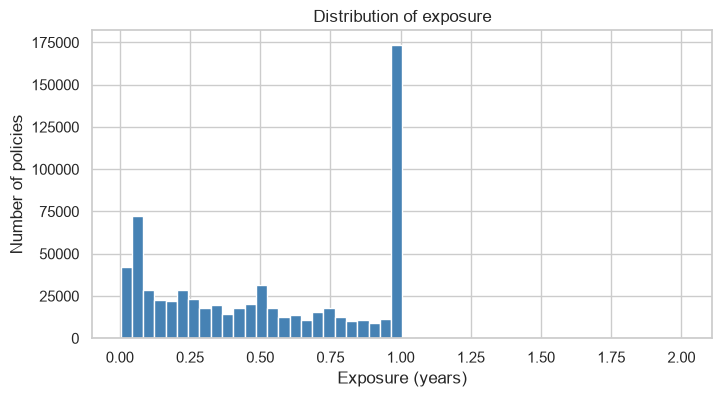

Policies with exposure > 1 year: 1224


In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df["Exposure"], bins=50, color="steelblue")
ax.set_xlabel("Exposure (years)")
ax.set_ylabel("Number of policies")
ax.set_title("Distribution of exposure")
plt.show()

print(f"Policies with exposure > 1 year: {(df['Exposure'] > 1).sum()}")

In [13]:
overall_freq = df["ClaimNb"].sum() / df["Exposure"].sum()
print(f"Total claims: {df['ClaimNb'].sum():,}")
print(f"Total exposure: {df['Exposure'].sum():,.0f} policy-years")
print(f"Portfolio claim frequency: {overall_freq:.4f} claims per policy-year")

Total claims: 36,102
Total exposure: 358,499 policy-years
Portfolio claim frequency: 0.1007 claims per policy-year


**Key findings:**
- 95% of policies have no claims, so the target is highly zero-inflated and a Poisson model is appropriate.
- Only 16 policies have 4 or more claims (up to 16); these extreme values will be capped at 4.
- Exposure varies between policies, so we model claim frequency (ClaimNb / Exposure) with exposure as a sample weight.
- 1,224 policies have exposure above 1 year, which is likely a data error; they will be capped at 1.
- The portfolio claim frequency is 0.101 claims per policy-year (about one claim every ten policy-years).

### 1.2 Claim frequency by risk factor
For each variable we plot the observed claim frequency (red) against the exposure in each group (grey bars).
The dashed line is the portfolio average.

In [14]:
def plot_frequency(data, feature, bins=None, title=None):
    d = data[[feature, "ClaimNb", "Exposure"]].copy()
    if bins is not None:
        d[feature] = pd.cut(d[feature], bins=bins, right=False)

    g = d.groupby(feature, observed=True).agg(
        claims=("ClaimNb", "sum"), exposure=("Exposure", "sum")
    )
    g["frequency"] = g["claims"] / g["exposure"]

    fig, ax1 = plt.subplots(figsize=(10, 4))
    labels = g.index.astype(str)
    ax1.bar(labels, g["exposure"], color="lightgrey")
    ax1.set_ylabel("Exposure (policy-years)")
    ax1.tick_params(axis="x", rotation=45)

    ax2 = ax1.twinx()
    ax2.plot(labels, g["frequency"], color="firebrick", marker="o")
    ax2.axhline(overall_freq, color="black", linestyle="--", linewidth=1, label="Portfolio average")
    ax2.set_ylabel("Claim frequency")
    ax2.grid(False)
    ax2.legend(loc="upper right")

    ax1.set_title(title or f"Claim frequency by {feature}")
    plt.tight_layout()
    plt.show()
    return g.round(4)

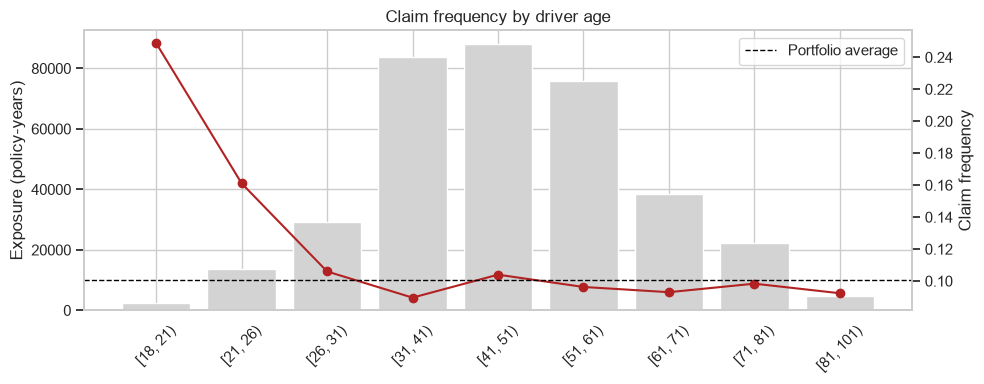

,claims,exposure,frequency
DrivAge,,,
"[18, 21)",643,2584.5828,0.2488
"[21, 26)",2198,13643.3204,0.1611
"[26, 31)",3093,29180.2338,0.1060
"[31, 41)",7522,83937.2990,0.0896
"[41, 51)",9165,88138.3102,0.1040
"[51, 61)",7292,75727.6360,0.0963
"[61, 71)",3566,38332.6885,0.0930
"[71, 81)",2188,22246.0831,0.0984
"[81, 101)",435,4709.2915,0.0924


In [15]:
plot_frequency(df, "DrivAge", bins=[18, 21, 26, 31, 41, 51, 61, 71, 81, 101],
               title="Claim frequency by driver age")

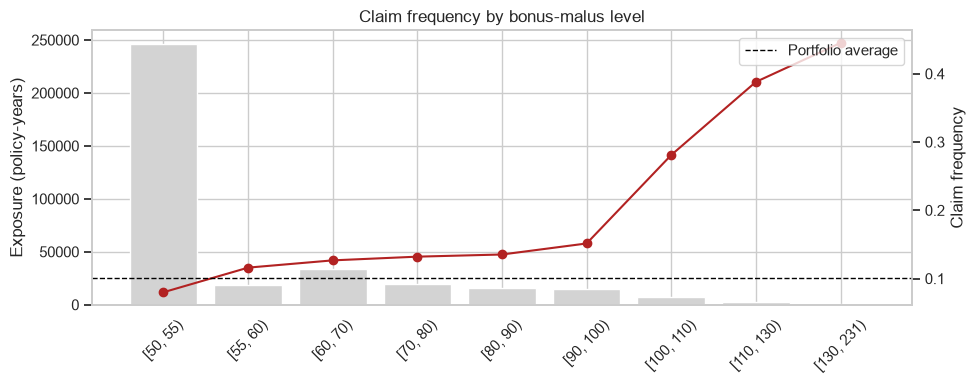

,claims,exposure,frequency
BonusMalus,,,
"[50, 55)",19719,246658.9899,0.0799
"[55, 60)",2135,18405.6640,0.1160
"[60, 70)",4326,34161.9736,0.1266
"[70, 80)",2594,19642.9239,0.1321
"[80, 90)",2084,15410.7864,0.1352
"[90, 100)",2181,14406.9153,0.1514
"[100, 110)",2008,7146.8564,0.2810
"[110, 130)",893,2301.3730,0.3880
"[130, 231)",162,363.9629,0.4451


In [18]:
plot_frequency(df, "BonusMalus", bins=[50, 55, 60, 70, 80, 90, 100, 110, 130, 231],
               title="Claim frequency by bonus-malus level")

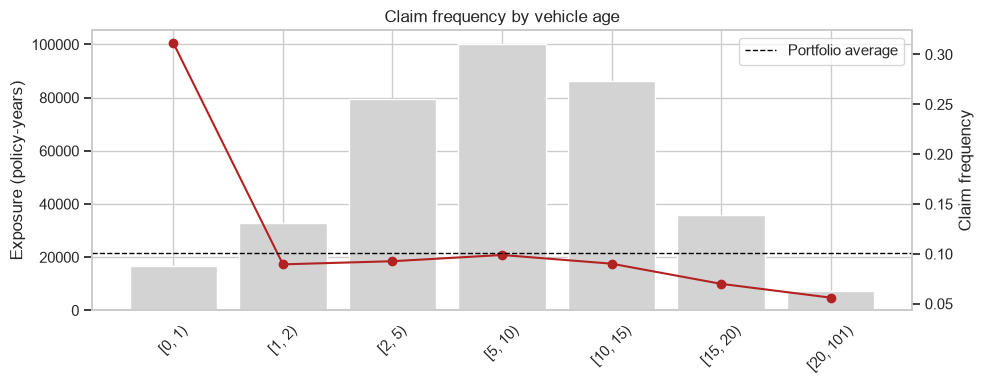

,claims,exposure,frequency
VehAge,,,
"[0, 1)",5205,16719.0287,0.3113
"[1, 2)",2931,32749.5376,0.0895
"[2, 5)",7370,79548.8476,0.0926
"[5, 10)",9914,100255.4378,0.0989
"[10, 15)",7764,86098.4538,0.0902
"[15, 20)",2517,35981.1643,0.0700
"[20, 101)",401,7146.9756,0.0561


In [16]:
plot_frequency(df, "VehAge", bins=[0, 1, 2, 5, 10, 15, 20, 101],
               title="Claim frequency by vehicle age")

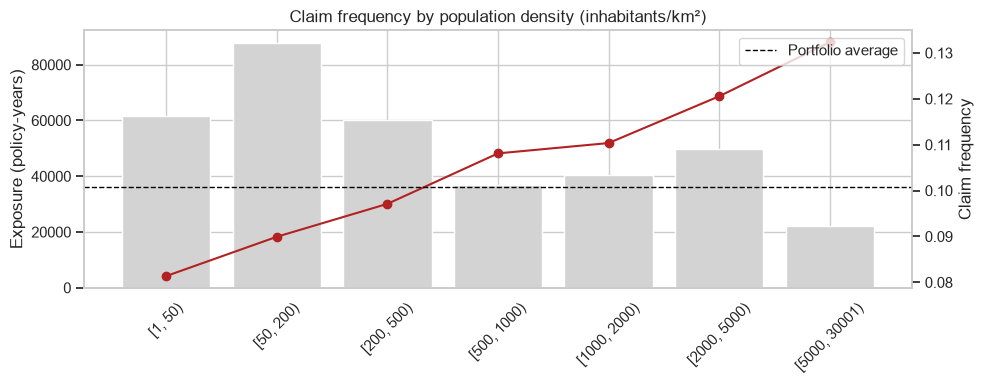

,claims,exposure,frequency
Density,,,
"[1, 50)",5002,61472.8794,0.0814
"[50, 200)",7904,87892.4626,0.0899
"[200, 500)",5832,60060.3835,0.0971
"[500, 1000)",3982,36835.4706,0.1081
"[1000, 2000)",4446,40289.7011,0.1104
"[2000, 5000)",5989,49680.2465,0.1206
"[5000, 30001)",2947,22268.3018,0.1323


In [17]:
plot_frequency(df, "Density", bins=[1, 50, 200, 500, 1000, 2000, 5000, 30001],
               title="Claim frequency by population density (inhabitants/km²)")

**Key findings so far:**
- **Bonus-malus:** this is the strongest risk factor in the data. 69% of the exposure sits at level 50 (maximum bonus), with a frequency of 0.080, 20% below average. Frequency rises steadily with the level and jumps once the driver enters the malus zone (100+), reaching 0.445 above 130, about 4.4 times the average. Since bonus-malus summarises past claims history, this confirms that past claims are a strong predictor of future claims.
- **Driver age:** drivers aged 18–20 have a claim frequency of 0.249, about 2.5 times the portfolio average, and drivers aged 21–25 are still 60% above it. Risk falls to its lowest level at ages 31–40 (0.090). The small increase at 41–50 (0.104) could be explained by younger family members driving the policyholder's car.
- **Vehicle age:** vehicles under one year old show a frequency of 0.311, three times the average. This looks anomalous and may be linked to short policy durations for new cars, so it should be treated with caution. Frequency is stable for vehicles aged 1–15 and drops for older vehicles (0.056 for 20+ years), probably because they are driven less.
- **Population density:** frequency rises steadily from 0.081 in the least dense areas to 0.132 in the densest (+63%). Given its wide range, density will enter the model on a log scale.

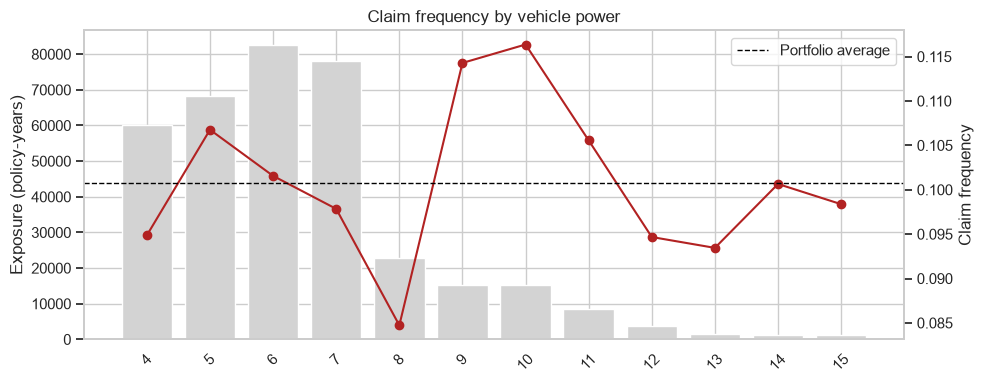

,claims,exposure,frequency
VehPower,,,
4,5699,60073.6373,0.0949
5,7278,68173.3488,0.1068
6,8381,82524.2102,0.1016
7,7627,77950.4567,0.0978
8,1922,22684.6163,0.0847
9,1754,15348.2137,0.1143
10,1789,15375.0108,0.1164
11,897,8497.7785,0.1056
12,359,3792.0383,0.0947


In [19]:
plot_frequency(df, "VehPower", title="Claim frequency by vehicle power")

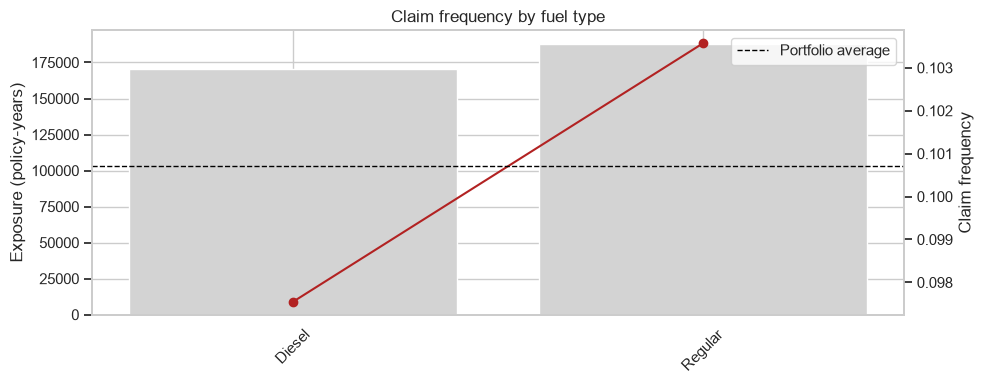

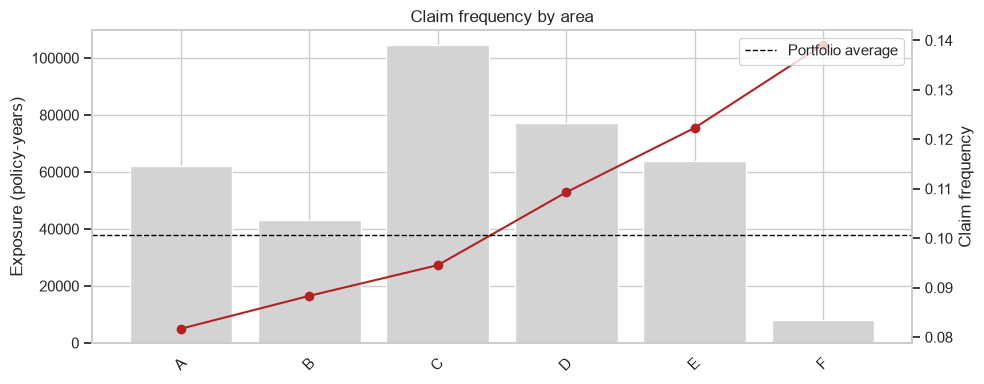

,claims,exposure,frequency
Area,,,
A,5063,61969.3777,0.0817
B,3800,43012.3239,0.0883
C,9875,104449.0038,0.0945
D,8428,77120.1917,0.1093
E,7805,63819.3143,0.1223
F,1131,8129.2341,0.1391


In [20]:
plot_frequency(df, "VehGas", title="Claim frequency by fuel type")
plot_frequency(df, "Area", title="Claim frequency by area")

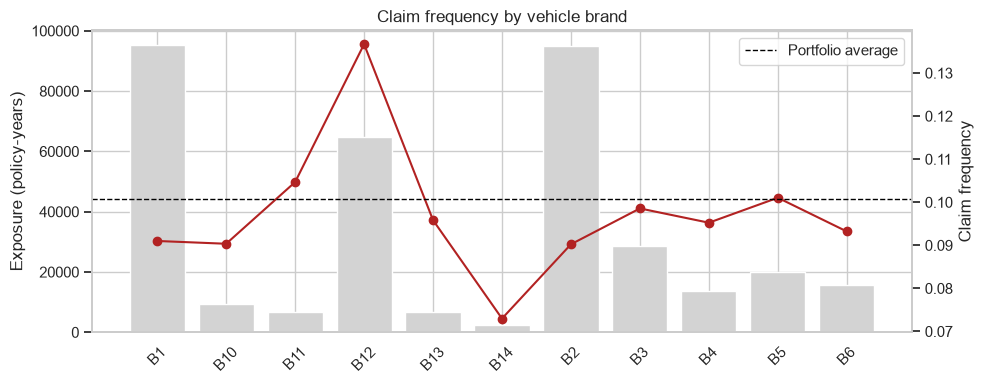

,claims,exposure,frequency
VehBrand,,,
B1,8677,95351.0596,0.0910
B10,858,9496.0141,0.0904
B11,721,6887.8173,0.1047
B12,8859,64808.6087,0.1367
B13,649,6772.0322,0.0958
B14,166,2274.4677,0.0730
B2,8560,94864.0571,0.0902
B3,2818,28592.8763,0.0986
B4,1312,13775.4961,0.0952


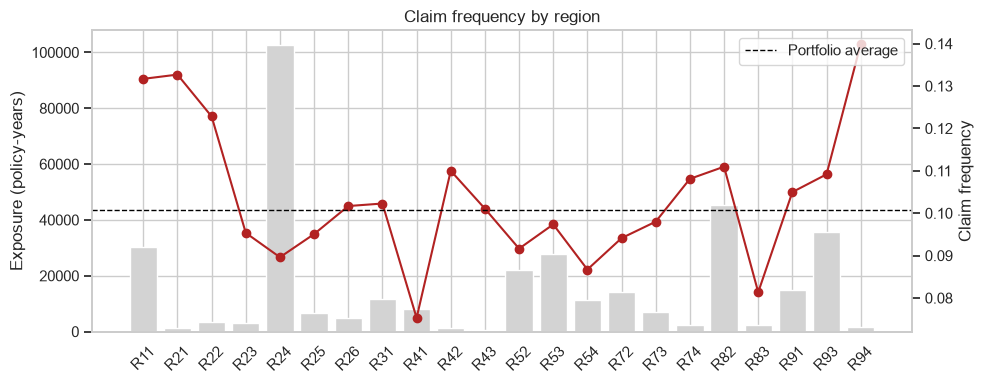

,claims,exposure,frequency
Region,,,
R11,3978,30208.6420,0.1317
R21,160,1205.8315,0.1327
R22,439,3574.4102,0.1228
R23,303,3177.6822,0.0954
R24,9204,102712.9034,0.0896
R25,633,6657.9011,0.0951
R26,511,5025.3586,0.1017
R31,1176,11497.9743,0.1023
R41,611,8113.7780,0.0753


In [25]:
display(plot_frequency(df, "VehBrand", title="Claim frequency by vehicle brand"))
display(plot_frequency(df, "Region", title="Claim frequency by region"))

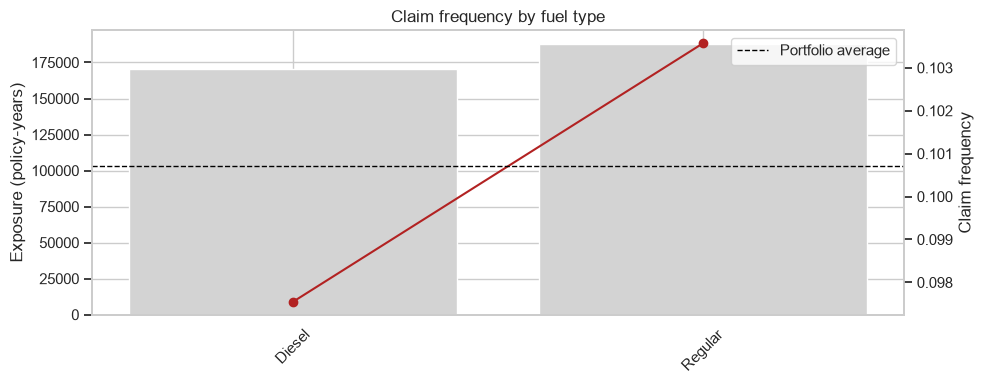

,claims,exposure,frequency
VehGas,,,
Diesel,16648,170660.8931,0.0976
Regular,19454,187838.5523,0.1036


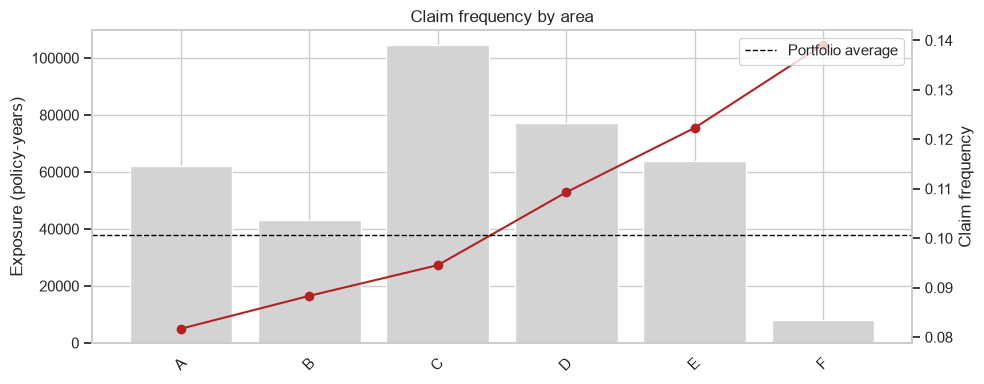

,claims,exposure,frequency
Area,,,
A,5063,61969.3777,0.0817
B,3800,43012.3239,0.0883
C,9875,104449.0038,0.0945
D,8428,77120.1917,0.1093
E,7805,63819.3143,0.1223
F,1131,8129.2341,0.1391


In [22]:
display(plot_frequency(df, "VehGas", title="Claim frequency by fuel type"))
display(plot_frequency(df, "Area", title="Claim frequency by area"))

In [26]:
df.groupby("Area")["Density"].agg(["min", "median", "max"])

,min,median,max
Area,,,
A,1,27.0,50
B,50,72.0,100
C,100,222.0,500
D,500,1054.0,1993
E,2001,3744.0,9850
F,10008,27000.0,27000


- **Area:** frequency rises steadily from zone A (0.082) to zone F (0.139), +70%, closely mirroring population density. The two variables are likely to be strongly related (checked above).
- **Region:** frequencies range from 0.075 (R41) to 0.140 (R94). R24 alone accounts for 29% of the exposure, so its estimate is very reliable, while several regions have under 2,000 policy-years and their extreme values may be noise.
- **Vehicle brand:** B12 stands out with a frequency of 0.137, 36% above average, and with a large exposure (64,809 policy-years), so the effect is not noise. All other brands sit between 0.090 and 0.105, except B14 (0.073), which has little exposure.
- **Vehicle power:** no clear trend (0.085–0.116); a weak risk factor on its own.
- **Fuel type:** diesel 0.098 vs regular 0.104, a small difference of about 6%.

In [27]:
new_car_share = (
    df.assign(new_car=(df["VehAge"] == 0))
      .groupby("VehBrand")["new_car"]
      .mean()
      .mul(100)
      .round(1)
      .sort_values(ascending=False)
)
new_car_share.to_frame("% of vehicles under 1 year")

,% of vehicles under 1 year
VehBrand,
B12,22.3
B11,7.1
B10,5.9
B3,5.4
B4,4.9
B6,3.9
B2,3.9
B14,3.7
B13,3.5


In [29]:
check = df.assign(
    brand=np.where(df["VehBrand"] == "B12", "B12", "Other brands"),
    vehicle=np.where(df["VehAge"] == 0, "Under 1 year", "1 year or older"),
)
g = check.groupby(["brand", "vehicle"]).agg(
    claims=("ClaimNb", "sum"), exposure=("Exposure", "sum")
)
g["frequency"] = (g["claims"] / g["exposure"]).round(4)
g

claims       exposure  frequency
brand        vehicle                                          
B12          1 year or older    4541   55247.971676     0.0822
             Under 1 year       4318    9560.637042     0.4516
Other brands 1 year or older   26356  286532.445058     0.0920
             Under 1 year        887    7158.391687     0.1239

### 1.3 Investigating the vehicle brand B12 anomaly
B12 has 22.3% of vehicles under one year old, compared with 3–7% for every other brand. Splitting by brand and vehicle age shows where the excess risk comes from:

| | 1 year or older | Under 1 year |
|---|---|---|
| **B12** | 0.082 | **0.452** |
| **Other brands** | 0.092 | 0.124 |

B12 vehicles aged one year or older are actually slightly *less* risky than other brands. The anomaly is concentrated in new B12 vehicles, with a frequency of 0.452 (about 4.5 times the portfolio average), and they account for 83% of all claims on new vehicles. This is an **interaction** between brand and vehicle age: neither variable explains it on its own. A standard GLM cannot capture it without an explicit interaction feature, whereas tree-based models such as LightGBM can learn it directly.

### 1.4 Summary and implications for modelling
- **Bonus-malus** is the strongest risk factor; **driver age** and **population density** also show clear patterns.
- **Area** is a binned version of **Density** (the density ranges of each zone do not overlap), so only log-density will be used.
- Vehicle power and fuel type have weak effects on their own; region shows differences, but several regions have little exposure.
- New B12 vehicles show a strong interaction effect, which will be added as an explicit feature for the GLM.
- Data cleaning before modelling: cap `ClaimNb` at 4 and `Exposure` at 1 year.

## 2. Data preparation
Based on the exploratory analysis:
- `ClaimNb` is capped at 4 and `Exposure` at 1 year.
- `Area` is dropped, since it is a binned version of `Density`; density is used on a log scale.
- A `B12_new` flag captures the interaction between brand B12 and vehicles under one year old (used by the GLM only).
- Driver age and vehicle age are grouped into the same bands used in the analysis, so the GLM can capture non-linear effects.

In [30]:
data = df.copy()

# Cap extreme values
data["ClaimNb"] = data["ClaimNb"].clip(upper=4)
data["Exposure"] = data["Exposure"].clip(upper=1)

# Target: claim frequency per policy-year
data["Frequency"] = data["ClaimNb"] / data["Exposure"]

# New features
data["LogDensity"] = np.log(data["Density"])
data["B12_new"] = ((data["VehBrand"] == "B12") & (data["VehAge"] == 0)).astype(int)
data["DrivAgeBand"] = pd.cut(data["DrivAge"], bins=[18, 21, 26, 31, 41, 51, 61, 71, 81, 101], right=False).astype(str)
data["VehAgeBand"] = pd.cut(data["VehAge"], bins=[0, 1, 2, 5, 10, 15, 20, 101], right=False).astype(str)

data = data.drop(columns=["Area"])

print(f"Max ClaimNb: {data['ClaimNb'].max()}, max Exposure: {data['Exposure'].max()}")
print(f"Portfolio frequency after cleaning: {data['ClaimNb'].sum() / data['Exposure'].sum():.4f}")
data.head()

Max ClaimNb: 4, max Exposure: 1.0
Portfolio frequency after cleaning: 0.1006


,IDpol,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region,Frequency,LogDensity,B12_new,DrivAgeBand,VehAgeBand
0,1,1,0.10,5,0,55,50,B12,Regular,1217,R82,10.000000,7.104144,1,"[51, 61)","[0, 1)"
1,3,1,0.77,5,0,55,50,B12,Regular,1217,R82,1.298701,7.104144,1,"[51, 61)","[0, 1)"
2,5,1,0.75,6,2,52,50,B12,Diesel,54,R22,1.333333,3.988984,0,"[51, 61)","[2, 5)"
3,10,1,0.09,7,0,46,50,B12,Diesel,76,R72,11.111111,4.330733,1,"[41, 51)","[0, 1)"
4,11,1,0.84,7,0,46,50,B12,Diesel,76,R72,1.190476,4.330733,1,"[41, 51)","[0, 1)"


In [31]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(data, test_size=0.2, random_state=42)

print(f"Train: {len(train):,} policies | Test: {len(test):,} policies")
for name, d in [("Train", train), ("Test", test)]:
    print(f"{name} frequency: {d['ClaimNb'].sum() / d['Exposure'].sum():.4f}")

Train: 542,410 policies | Test: 135,603 policies
Train frequency: 0.1005
Test frequency: 0.1011


In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

glm_categorical = ["DrivAgeBand", "VehAgeBand", "VehBrand", "VehPower", "VehGas", "Region"]
glm_numeric = ["BonusMalus", "LogDensity"]
glm_binary = ["B12_new"]

glm_preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), glm_categorical),
    ("num", StandardScaler(), glm_numeric),
    ("bin", "passthrough", glm_binary),
])

In [33]:
lgbm_features = ["BonusMalus", "DrivAge", "VehAge", "VehPower", "LogDensity", "VehBrand", "VehGas", "Region"]
lgbm_categorical = ["VehBrand", "VehGas", "Region"]

def prepare_lgbm(d):
    X = d[lgbm_features].copy()
    for col in lgbm_categorical:
        X[col] = pd.Categorical(X[col], categories=sorted(data[col].unique()))
    return X

X_train_lgbm = prepare_lgbm(train)
X_test_lgbm = prepare_lgbm(test)
X_train_lgbm.dtypes

BonusMalus       int64
DrivAge          int64
VehAge           int64
VehPower         int64
LogDensity     float64
VehBrand      category
VehGas        category
Region        category
dtype: object

## 3. Modelling

### 3.1 Poisson GLM
The GLM models the log of the expected claim frequency as a linear combination of the risk factors.
Exposure is used as a sample weight, so short policies contribute less to the fit.

In [34]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import PoissonRegressor

glm = Pipeline([
    ("prep", glm_preprocessor),
    ("model", PoissonRegressor(alpha=1e-4, max_iter=1000)),
])
glm.fit(train, train["Frequency"], model__sample_weight=train["Exposure"])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['IDpol','ClaimNb','Exposure',...,'B12_new','DrivAgeBand','VehAgeBand']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis 

In [35]:
from sklearn.metrics import mean_poisson_deviance, d2_tweedie_score

def evaluate(name, pred_train, pred_test):
    rows = []
    for split, d, pred in [("Train", train, pred_train), ("Test", test, pred_test)]:
        rows.append({
            "Model": name,
            "Split": split,
            "Poisson deviance": mean_poisson_deviance(d["Frequency"], pred, sample_weight=d["Exposure"]),
            "D² (deviance explained)": d2_tweedie_score(d["Frequency"], pred, sample_weight=d["Exposure"], power=1),
            "Predicted claims": (pred * d["Exposure"]).sum(),
            "Actual claims": d["ClaimNb"].sum(),
        })
    return pd.DataFrame(rows)

# Baseline: predict the same average frequency for everyone
base_freq = train["ClaimNb"].sum() / train["Exposure"].sum()

results = pd.concat([
    evaluate("Baseline (portfolio average)", np.full(len(train), base_freq), np.full(len(test), base_freq)),
    evaluate("Poisson GLM", glm.predict(train), glm.predict(test)),
])
results.round(4)

,Model,Split,Poisson deviance,D² (deviance explained),Predicted claims,Actual claims
0,Baseline (portfolio average),Train,0.6243,0.0000,28817.0000,28817
1,Baseline (portfolio average),Test,0.6274,-0.0000,7194.7250,7239
0,Poisson GLM,Train,0.5874,0.0590,28804.9465,28817
1,Poisson GLM,Test,0.5944,0.0526,7170.9298,7239


In [36]:
feature_names = glm.named_steps["prep"].get_feature_names_out()
relativities = pd.DataFrame({
    "feature": feature_names,
    "relativity": np.exp(glm.named_steps["model"].coef_),
})
relativities[relativities["feature"].str.contains("DrivAgeBand|BonusMalus|LogDensity|B12_new")].round(3)

,feature,relativity
0,"cat__DrivAgeBand_[18, 21)",1.172
1,"cat__DrivAgeBand_[21, 26)",0.829
2,"cat__DrivAgeBand_[26, 31)",0.735
3,"cat__DrivAgeBand_[31, 41)",0.834
4,"cat__DrivAgeBand_[41, 51)",1.122
5,"cat__DrivAgeBand_[51, 61)",1.056
6,"cat__DrivAgeBand_[61, 71)",1.028
7,"cat__DrivAgeBand_[71, 81)",1.139
8,"cat__DrivAgeBand_[81, 101)",1.110
63,num__BonusMalus,1.418


In [37]:
data.groupby("DrivAgeBand", observed=True)["BonusMalus"].mean().round(1).to_frame("Average bonus-malus")

,Average bonus-malus
DrivAgeBand,
"[18, 21)",95.3
"[21, 26)",87.6
"[26, 31)",73.9
"[31, 41)",61.2
"[41, 51)",55.1
"[51, 61)",53.7
"[61, 71)",53.0
"[71, 81)",52.3
"[81, 101)",53.0


**GLM results:**
- The GLM reduces the test Poisson deviance from 0.6274 (baseline) to 0.5944, explaining 5.3% of the deviance. Low values are normal for claim frequency, which is largely driven by randomness.
- Train and test performance are close (5.9% vs 5.3%), so there is no sign of overfitting, and the model is well calibrated (7,171 predicted vs 7,239 actual claims on the test set).
- New B12 vehicles have a relativity of 3.94: almost four times the risk of an otherwise identical vehicle, confirming the interaction found in the analysis.
- Bonus-malus is the strongest continuous factor (+42% per standard deviation).
- Once bonus-malus is included, the effect of young age is much smaller than in the one-way analysis. Young drivers have not had time to earn a bonus, so their higher bonus-malus already captures much of their extra risk. This shows why multivariate models are needed: one-way analyses mix the effects of correlated variables.

### 3.2 LightGBM (gradient boosting)
LightGBM is trained with a Poisson objective on the raw features, without the `B12_new` flag, to test whether it can learn the interaction by itself.
A validation set taken from the training data is used for early stopping, so the test set stays untouched until the final evaluation.

In [41]:
import lightgbm as lgb

X_fit, X_val, y_fit, y_val, w_fit, w_val = train_test_split(
    X_train_lgbm, train["Frequency"], train["Exposure"], test_size=0.1, random_state=42
)

lgbm = lgb.LGBMRegressor(
    objective="poisson",
    n_estimators=3000,
    learning_rate=0.03,
    num_leaves=31,
    min_child_samples=200,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=42,
    verbose=-1,
)

lgbm.fit(
    X_fit, y_fit,
    sample_weight=w_fit,
    eval_X=X_val,
    eval_y=y_val,
    eval_sample_weight=[w_val],
    eval_metric="poisson",
    callbacks=[lgb.early_stopping(100), lgb.log_evaluation(200)],
)
print(f"Best number of trees: {lgbm.best_iteration_}")

Training until validation scores don't improve for 100 rounds
[200]	valid_0's poisson: 0.309765
[400]	valid_0's poisson: 0.30887
[600]	valid_0's poisson: 0.308503
[800]	valid_0's poisson: 0.308362
[1000]	valid_0's poisson: 0.308262
[1200]	valid_0's poisson: 0.308186
Early stopping, best iteration is:
[1272]	valid_0's poisson: 0.308146
Best number of trees: 1272


In [42]:
results = pd.concat([
    evaluate("Baseline (portfolio average)", np.full(len(train), base_freq), np.full(len(test), base_freq)),
    evaluate("Poisson GLM", glm.predict(train), glm.predict(test)),
    evaluate("LightGBM", lgbm.predict(X_train_lgbm), lgbm.predict(X_test_lgbm)),
])
results.round(4)

,Model,Split,Poisson deviance,D² (deviance explained),Predicted claims,Actual claims
0,Baseline (portfolio average),Train,0.6243,0.0000,28817.0000,28817
1,Baseline (portfolio average),Test,0.6274,-0.0000,7194.7250,7239
0,Poisson GLM,Train,0.5874,0.0590,28804.9465,28817
1,Poisson GLM,Test,0.5944,0.0526,7170.9298,7239
0,LightGBM,Train,0.5485,0.1214,28779.9393,28817
1,LightGBM,Test,0.5762,0.0815,7157.6928,7239


**Model comparison (test set):**

| Model | Poisson deviance | D² |
|---|---|---|
| Baseline (portfolio average) | 0.6274 | 0.0% |
| Poisson GLM | 0.5944 | 5.3% |
| LightGBM | 0.5762 | 8.2% |

- LightGBM explains about 55% more deviance than the GLM, even without the `B12_new` interaction feature, because it can capture non-linear effects and interactions automatically.
- LightGBM shows some overfitting (12.1% on train vs 8.2% on test), but its test performance is still clearly better. Stronger regularisation could narrow this gap.
- Both models are well calibrated at portfolio level (within about 1% of the actual number of claims).
- The average bonus-malus falls from 95.3 for drivers aged 18–20 to around 53 for drivers over 50, which confirms why the GLM attributes much of the young-driver risk to bonus-malus rather than to age.

### 3.3 Risk ranking: Lorenz curve and Gini coefficient
Policies are sorted from lowest to highest predicted risk. A model that ranks risk well concentrates the actual claims in the policies it predicts as riskiest, so its curve moves away from the diagonal.

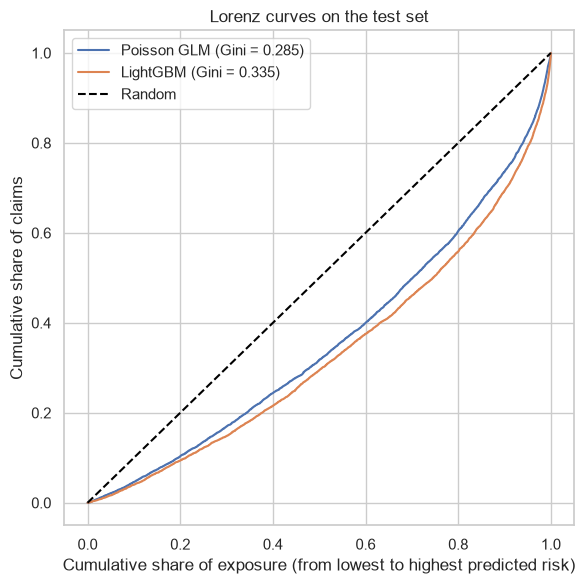

In [43]:
def lorenz_curve(claims, pred, exposure):
    order = np.argsort(pred)
    cum_exposure = np.cumsum(exposure[order]) / exposure.sum()
    cum_claims = np.cumsum(claims[order]) / claims.sum()
    return np.insert(cum_exposure, 0, 0), np.insert(cum_claims, 0, 0)

fig, ax = plt.subplots(figsize=(6, 6))
for label, pred in [("Poisson GLM", glm.predict(test)), ("LightGBM", lgbm.predict(X_test_lgbm))]:
    x, y = lorenz_curve(test["ClaimNb"].values, pred, test["Exposure"].values)
    gini = 1 - 2 * np.trapezoid(y, x)
    ax.plot(x, y, label=f"{label} (Gini = {gini:.3f})")

ax.plot([0, 1], [0, 1], linestyle="--", color="black", label="Random")
ax.set_xlabel("Cumulative share of exposure (from lowest to highest predicted risk)")
ax.set_ylabel("Cumulative share of claims")
ax.set_title("Lorenz curves on the test set")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

In [46]:
for label, pred in [("Poisson GLM", glm.predict(test)), ("LightGBM", lgbm.predict(X_test_lgbm))]:
    x, y = lorenz_curve(test["ClaimNb"].values, pred, test["Exposure"].values)
    gini = 1 - 2 * np.trapezoid(y, x)
    print(f"{label}: Gini = {gini:.3f}")

Poisson GLM: Gini = 0.285
LightGBM: Gini = 0.335


**Risk ranking:** both models rank risk well, but LightGBM's curve lies further from the diagonal across the whole range, with a Gini coefficient of 0.335 against 0.285 for the GLM (an 18% improvement). Better ranking lets an insurer offer lower prices to low-risk drivers while charging high-risk drivers enough to cover their expected claims.

## 4. Model interpretation with SHAP
SHAP values break each LightGBM prediction down into the contribution of every feature, which makes the model explainable to business stakeholders.

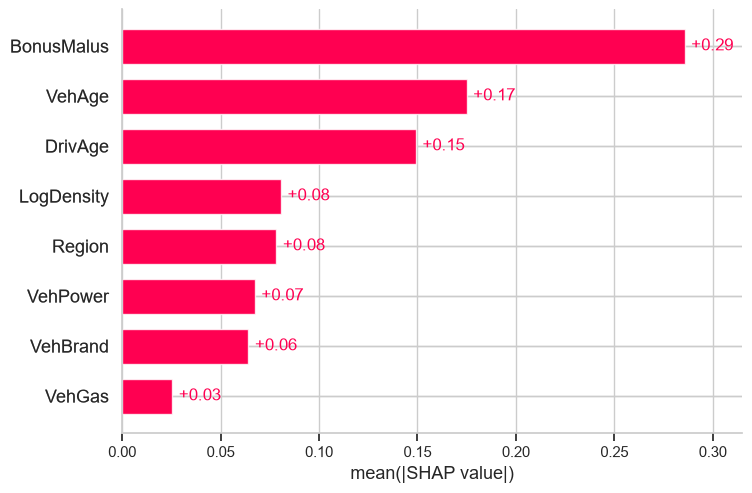

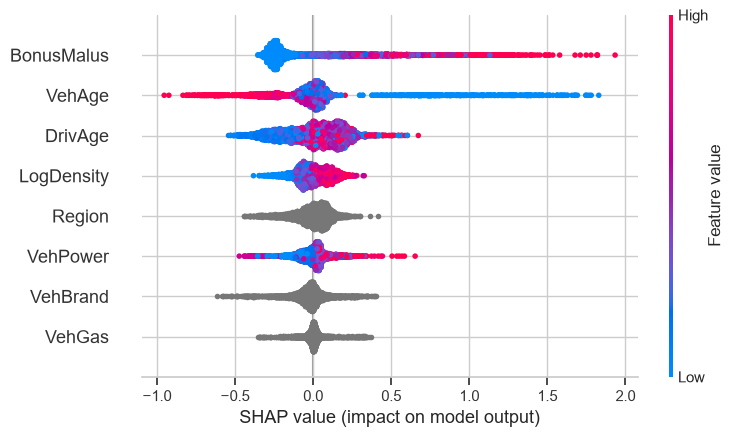

In [44]:
import shap

X_sample = X_test_lgbm.sample(5000, random_state=42)
explainer = shap.TreeExplainer(lgbm)
shap_values = explainer(X_sample)

shap.plots.bar(shap_values, max_display=10)
shap.plots.beeswarm(shap_values, max_display=10)

In [45]:
check = test.assign(
    pred_glm=glm.predict(test),
    pred_lgbm=lgbm.predict(X_test_lgbm),
    brand=np.where(test["VehBrand"] == "B12", "B12", "Other brands"),
    vehicle=np.where(test["VehAge"] == 0, "Under 1 year", "1 year or older"),
)

def weighted_summary(g):
    w = g["Exposure"]
    return pd.Series({
        "Actual frequency": g["ClaimNb"].sum() / w.sum(),
        "GLM prediction": (g["pred_glm"] * w).sum() / w.sum(),
        "LightGBM prediction": (g["pred_lgbm"] * w).sum() / w.sum(),
    })

check.groupby(["brand", "vehicle"]).apply(weighted_summary).round(4)

Actual frequency  GLM prediction  \
brand        vehicle                                             
B12          1 year or older            0.0821          0.0838   
             Under 1 year               0.4320          0.4543   
Other brands 1 year or older            0.0933          0.0912   
             Under 1 year               0.1324          0.1264   

                              LightGBM prediction  
brand        vehicle                               
B12          1 year or older               0.0831  
             Under 1 year                  0.4515  
Other brands 1 year or older               0.0911  
             Under 1 year                  0.1273

**SHAP findings:**
- Bonus-malus is the most important feature: high values push the predicted frequency up strongly.
- Vehicle age is the second most important feature, mainly because of new vehicles (blue points far to the right), which reflects the new-vehicle anomaly found in the analysis.
- Driver age ranks third. Its effect is more moderate than in the one-way analysis, since part of the young-driver risk is already captured by bonus-malus.
- Higher population density increases risk, while fuel type has the smallest impact, consistent with the exploratory analysis.
- SHAP values are on the log scale of the Poisson model: a contribution of +0.29 multiplies the expected frequency by about 1.34.

**Did LightGBM learn the B12 interaction?**

| Group (test set) | Actual | GLM | LightGBM |
|---|---|---|---|
| B12, under 1 year | 0.432 | 0.454 | 0.452 |
| B12, 1 year or older | 0.082 | 0.084 | 0.083 |
| Other brands, under 1 year | 0.132 | 0.126 | 0.127 |
| Other brands, 1 year or older | 0.093 | 0.091 | 0.091 |

Yes. LightGBM predicts 0.452 for new B12 vehicles without ever seeing the `B12_new` feature: it learned the interaction by combining brand and vehicle age in its trees. The GLM only reaches a similar value because the interaction was found during the analysis and added by hand. In a real portfolio with many more variables, finding every interaction manually is not feasible, which is a key advantage of gradient boosting.

## 5. Conclusions
- **Bonus-malus** is the strongest predictor of claim frequency, followed by vehicle age, driver age and population density.
- **LightGBM outperforms the Poisson GLM** on the test set: it explains 8.2% of the deviance against 5.3%, and ranks risk better (Gini 0.335 vs 0.285). Both models are well calibrated at portfolio level.
- **LightGBM learns interactions automatically**, such as the high risk of new B12 vehicles, which the GLM can only capture if the interaction is found and added by hand.
- **The GLM remains valuable for its transparency:** its relativities are easy to explain to business and regulators. In practice, insurers often combine both approaches, using machine learning to find patterns and GLMs, or explainability tools like SHAP, to communicate them.

**Limitations and next steps:**
- Some policyholders appear more than once with split policies, so a few may fall in both train and test, which could slightly overstate performance. A grouped split by policyholder would avoid this.
- The cause of the new B12 vehicle anomaly is unknown (it could be a data artefact or a specific customer segment such as fleets) and would need to be investigated with the business.
- This project models claim frequency only. A full pricing model would add a severity model (for example, a Gamma GLM) to estimate the pure premium.
- LightGBM shows some overfitting; tuning its hyperparameters with cross-validation could improve it further.